In [28]:
#1. IMPORTING LIBRARIES & LOADING DATASET
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Check if housing.csv exists, and if not, download a common version
import os
if not os.path.exists('housing.csv'):
    print('Downloading housing.csv...')
    !wget -q https://raw.githubusercontent.com/ageron/handson-ml/master/datasets/housing/housing.csv
    print('Download complete.')

dataset = pd.read_csv('housing.csv')
dataset.head()
dataset

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND


### Data Overview: Attributes, Data Types, and Missing Values

In [29]:
print('Dataset Information:')
display(dataset.info())

print('\nMissing values per column:')
display(dataset.isnull().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


None


Missing values per column:


,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,207
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


In [30]:
display(dataset.describe())

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


### Correlation Heatmap

### Correlation Heatmap

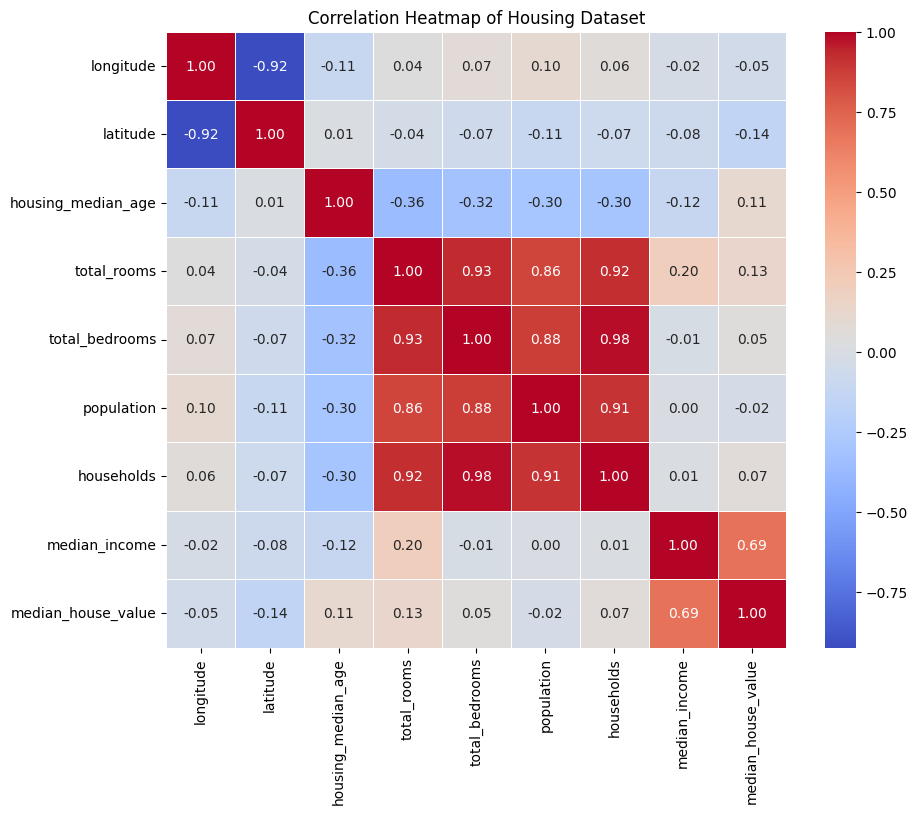

In [31]:
import pandas as pd
import os
import seaborn as sns
import matplotlib.pyplot as plt

# Check if housing.csv exists, and if not, download a common version
if not os.path.exists('housing.csv'):
    print('Downloading housing.csv...')
    !wget -q https://raw.githubusercontent.com/ageron/handson-ml/master/datasets/housing/housing.csv
    print('Download complete.')

dataset = pd.read_csv('housing.csv')

plt.figure(figsize=(10, 8))
sns.heatmap(dataset.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Heatmap of Housing Dataset')
plt.show()

### Brief Correlation Summary

**Strong Positive Correlations (closer to +1.00):**
*   total_rooms, total_bedrooms, population, and households are highly correlated with each other, as they often scale together.
*   median_income and median_house_value have a strong positive correlation (0.69), indicating higher incomes often lead to higher house values.

**Weak Positive Correlations (closer to +0.00 but still positive):**
*   total_rooms and median_income (0.20).
*   total_rooms and median_house_value (0.13).
*   households and median_house_value (0.07).
*   total_bedrooms and median_house_value (0.05).
*   housing_median_age and median_house_value (0.11).




The heatmap shows how strongly each numeric feature in the housing dataset relates to the others:

median_income and median_house_value have the strongest meaningful correlation (0.69) — higher income areas tend to have higher house values.
total_rooms, total_bedrooms, population, and households are all strongly correlated with each other (close to 1.00), since they naturally scale together (more rooms/bedrooms → more households/population).
Most other features (housing_median_age, total_rooms, total_bedrooms, households) show only weak correlation with median_house_value (roughly 0.05–0.20), meaning they have little direct linear influence on price on their own.

In [33]:
#2.1 Define the target variable y (median_house_value)
y = dataset['median_house_value'].values

#2.2 Define the independent variables X
# Exclude 'median_house_value' (target) and 'ocean_proximity' (categorical) from X
X = dataset.drop(columns=['median_house_value', 'ocean_proximity']).values

#2.3 Handle missing values in X_numerical using median imputation
imputer = SimpleImputer(strategy='median')
X = imputer.fit_transform(X)

# Display the shapes to confirm
print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

NameError: name 'SimpleImputer' is not defined

In [ ]:
# Convert the NumPy array X back to a pandas DataFrame and display it
import pandas as pd

X_df = pd.DataFrame(X, columns=dataset.drop(columns=['median_house_value', 'ocean_proximity']).columns)
display(X_df.head())

In [ ]:
X_df.info()
X_df.describe()

In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler(feature_range=(0, 1))
rescaledX = scaler.fit_transform(X)

print(rescaledX)

SPLITTING THE DATASET

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(rescaledX, y, test_size=0.30, random_state=0)

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(rescaledX, y, test_size=0.30, random_state=0)

regressor = LinearRegression()
regressor.fit(X_train, y_train)

In [ ]:
pd.DataFrame(regressor.coef_)

In [ ]:
y_pred = regressor.predict(X_test)
y_pred

In [ ]:
#plot for the TRAIN

# Select the 'median_income' feature for visualization (it's at index 7 in X_train)
X_train_median_income = X_train[:, 7]

# Create an array of predictions for the training set
y_train_pred = regressor.predict(X_train)

# Create a DataFrame to sort both X_train_median_income and y_train_pred simultaneously for coherent plotting
import pandas as pd
plot_data = pd.DataFrame({'median_income': X_train_median_income, 'predictions': y_train_pred})
plot_data_sort = plot_data.sort_values(by='median_income')

plt.figure(figsize=(8, 6))
plt.scatter(X_train[:, 7], y_train, color='blue', label='Actual')
plt.plot(plot_data_sort['median_income'], plot_data_sort['predictions'], color='red', linewidth=2, label='Predicted')
plt.title('Training Set: Median Income vs Median House Value')
plt.xlabel('Median Income (Scaled)')
plt.ylabel('Median House Value')
plt.legend()
plt.show()

In [ ]:
y_pred2 = regressor.predict(rescaledX)
y_pred2

In [ ]:
dataset['Predicted House Value'] = y_pred2
dataset.head()

In [ ]:
actual_predicted = pd.DataFrame({"Actual_Median_House_Value": y_test, "Predicted House Value": y_pred})
display(actual_predicted)

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2_value = r2_score(y_test, y_pred)

print(f"MAE = {mae}")
print(f"MSE = {mse}")
print(f"r2_score = {r2_value}")

In [ ]:
#assignment: Apply other preprocessing methods
#what if we convert the caregorical data
#compare teh MAE, MSE, and R2_score

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Check if housing.csv exists, and if not, download a common version
import os
if not os.path.exists('housing.csv'):
    print('Downloading housing.csv...')
    !wget -q https://raw.githubusercontent.com/ageron/handson-ml/master/datasets/housing/housing.csv
    print('Download complete.')

dataset = pd.read_csv('housing.csv')

# target variable median_house_value
y = dataset['median_house_value'].values

# remove median_house_value, ocean_proximity'
X_numerical = dataset.drop(['median_house_value', 'ocean_proximity'], axis=1)


# remove null
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='median')
X = imputer.fit_transform(X_numerical)

In [ ]:
#Other Preprocessing
from sklearn.preprocessing import MinMaxScaler, StandardScaler, Binarizer, Normalizer

# MinMaxScaler
minmax_scaler = MinMaxScaler(feature_range=(0, 1))
X_minmax = minmax_scaler.fit_transform(X)

# StandardScaler
standard_scaler = StandardScaler()
X_standard = standard_scaler.fit_transform(X)

# Binarizer
binarizer = Binarizer(threshold=1)
X_binarized = binarizer.fit_transform(X)

# Normalizer
normalizer = Normalizer()
X_normalized = normalizer.fit_transform(X)

In [ ]:
from sklearn.model_selection import train_test_split

X_train_mm, X_test_mm, y_train_mm, y_test_mm = train_test_split(X_minmax, y, test_size=.30, random_state=0)
X_train_std, X_test_std, y_train_std, y_test_std = train_test_split(X_standard, y, test_size=.30, random_state=0)
X_train_bin, X_test_bin, y_train_bin, y_test_bin = train_test_split(X_binarized, y, test_size=.30, random_state=0)
X_train_norm, X_test_norm, y_train_norm, y_test_norm = train_test_split(X_normalized, y, test_size=.30, random_state=0)

In [ ]:
from sklearn.linear_model import LinearRegression

reg_mm = LinearRegression().fit(X_train_mm, y_train_mm)
reg_std = LinearRegression().fit(X_train_std, y_train_std)
reg_bin = LinearRegression().fit(X_train_bin, y_train_bin)
reg_norm = LinearRegression().fit(X_train_norm, y_train_norm)

In [ ]:
y_pred_mm = reg_mm.predict(X_test_mm)
y_pred_std = reg_std.predict(X_test_std)
y_pred_bin = reg_bin.predict(X_test_bin)
y_pred_norm = reg_norm.predict(X_test_norm)

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# MinMaxScaler metrics
mae_mm = mean_absolute_error(y_test_mm, y_pred_mm)
mse_mm = mean_squared_error(y_test_mm, y_pred_mm)
r2_mm = r2_score(y_test_mm, y_pred_mm)

# StandardScaler metrics
mae_std = mean_absolute_error(y_test_std, y_pred_std)
mse_std = mean_squared_error(y_test_std, y_pred_std)
r2_std = r2_score(y_test_std, y_pred_std)

# Binarizer metrics
mae_bin = mean_absolute_error(y_test_bin, y_pred_bin)
mse_bin = mean_squared_error(y_test_bin, y_pred_bin)
r2_bin = r2_score(y_test_bin, y_pred_bin)

# Normalizer metrics
mae_norm = mean_absolute_error(y_test_norm, y_pred_norm)
mse_norm = mean_squared_error(y_test_norm, y_pred_norm)
r2_norm = r2_score(y_test_norm, y_pred_norm)


In [ ]:
print("MAE:")
print(f"  MinMaxScaler: {mae_mm}")
print(f"  StandardScaler: {mae_std}")
print(f"  Binarizer: {mae_bin}")
print(f"  Normalizer: {mae_norm}")

print("\nMSE:")
print(f"  MinMaxScaler: {mse_mm}")
print(f"  StandardScaler: {mse_std}")
print(f"  Binarizer: {mse_bin}")
print(f"  Normalizer: {mse_norm}")

print("\nR2 Score:")
print(f"  MinMaxScaler: {r2_mm}")
print(f"  StandardScaler: {r2_std}")
print(f"  Binarizer: {r2_bin}")
print(f"  Normalizer: {r2_norm}")

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn import metrics
from sklearn.feature_selection import RFE
from sklearn.impute import SimpleImputer # Import SimpleImputer

# Assuming X_numerical and y are already defined from previous cells

# Impute missing values in X_numerical before RFE
imputer = SimpleImputer(strategy='median')
# Fit and transform X_numerical, then convert back to DataFrame to retain column names
# Store column names first, as fit_transform returns a NumPy array
numerical_cols = X_numerical.columns
X_numerical_imputed = imputer.fit_transform(X_numerical)
X_numerical_imputed_df = pd.DataFrame(X_numerical_imputed, columns=numerical_cols)


# 1. Perform RFE to get feature rankings
estimator = LinearRegression()
# Use the imputed DataFrame for RFE
rfe = RFE(estimator=estimator, n_features_to_select=8) # Select 8 features, as per X_numerical columns
rfe.fit(X_numerical_imputed_df, y)

# Create a DataFrame for RFE ranking
rfe_ranking = pd.DataFrame({
    'Feature': X_numerical_imputed_df.columns, # Use the imputed DataFrame's columns
    'Rank': rfe.ranking_, # Corrected from rfe.rankings_ to rfe.ranking_
    'Selected': rfe.support_
})

# 2. Identify RFE-selected features
# Based on the previous RFE output, selected features have rank 1
rfe_selected = rfe_ranking[rfe_ranking['Rank'] == 1]['Feature'].tolist()

print(f'RFE Selected Features: {rfe_selected}')

In [ ]:
# 2. Create a new dataset (X_rfe_df) with only these selected features
X_rfe_df = X_numerical_imputed_df[rfe_selected]

In [ ]:
# 3. Rescale the new dataset using the same MinMaxScaler
scaled_rfe = MinMaxScaler(feature_range=(0, 1))
rescaled_rfe = scaled_rfe.fit_transform(X_rfe_df)

In [ ]:
# 4. Split the new dataset into training and testing sets (consistent with original split)
X_train_rfe, X_test_rfe, y_train_rfe, y_test_rfe = train_test_split(
    rescaled_rfe, y,
    test_size=0.30,
    random_state=0
)


In [ ]:
from sklearn.impute import SimpleImputer

# Re-impute missing values in X_train_rfe and X_test_rfe just in case
# This step is added as a safeguard against any lingering NaNs,
# especially after scaling, as sklearn estimators don't handle them by default.
imputer_final = SimpleImputer(strategy='median')

X_train_rfe_imputed = imputer_final.fit_transform(X_train_rfe)
X_test_rfe_imputed = imputer_final.transform(X_test_rfe)

# 5. Train a new Linear Regression model on the RFE-selected features
regressor_rfe = LinearRegression()
regressor_rfe.fit(X_train_rfe_imputed, y_train_rfe)

In [ ]:
# 6. Make predictions with the new model
y_pred_rfe = regressor_rfe.predict(X_test_rfe_imputed)

In [ ]:
# 7. Compare the results
mae_rfe = metrics.mean_absolute_error(y_test_rfe, y_pred_rfe)
mse_rfe = metrics.mean_squared_error(y_test_rfe, y_pred_rfe)
rmse_rfe = np.sqrt(mse_rfe)
r2_rfe = metrics.r2_score(y_test_rfe, y_pred_rfe)

print(f'MAE(RFE): {mae_rfe:.2f}')
print(f'MSE(RFE): {mse_rfe:.2f}')
print(f'RMSE(RFE): {rmse_rfe:.2f}')
print(f'R2 SCORE(RFE): {r2_rfe:.2f}')

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import MinMaxScaler
from sklearn import metrics
import numpy as np
from sklearn.decomposition import PCA

# Ensure X_minmax exists (create it if missing)
if 'X_minmax' not in globals():
    scaler = MinMaxScaler()
    X_minmax = scaler.fit_transform(X)
    print("X_minmax was not found — created it from X using MinMaxScaler.")

# PCA
pca = PCA(n_components=4)
X_pca = pca.fit_transform(X_minmax)

X_train_pca, X_test_pca, y_train_pca, y_test_pca = train_test_split(X_pca, y, test_size=0.30, random_state=0)

regressor_pca = LinearRegression()
regressor_pca.fit(X_train_pca, y_train_pca)

y_pred_pca = regressor_pca.predict(X_test_pca)

mae_pca = metrics.mean_absolute_error(y_test_pca, y_pred_pca)
mse_pca = metrics.mean_squared_error(y_test_pca, y_pred_pca)
rmse_pca = np.sqrt(mse_pca)
r2_pca = metrics.r2_score(y_test_pca, y_pred_pca)

print(f'--- PCA Results (4 Components) ---')
print(f'MAE(PCA): {mae_pca:.2f}')
print(f'MSE(PCA): {mse_pca:.2f}')
print(f'RMSE(PCA): {rmse_pca:.2f}')
print(f'R2 SCORE(PCA): {r2_pca:.2f}')

# Comparison table: PCA vs RFE
if all(v in globals() for v in ['mae_rfe', 'mse_rfe', 'rmse_rfe', 'r2_rfe']):
    comparison_df = pd.DataFrame({
        'Metric': ['MAE', 'MSE', 'RMSE', 'R2 Score'],
        'PCA (4 Components)': [mae_pca, mse_pca, rmse_pca, r2_pca],
        'RFE': [mae_rfe, mse_rfe, rmse_rfe, r2_rfe]
    }).set_index('Metric')

    comparison_df['Difference (PCA - RFE)'] = comparison_df['PCA (4 Components)'] - comparison_df['RFE']

    print(f'\n--- Comparison: PCA vs RFE ---')
    print(comparison_df.round(4))
else:
    print(f'\nWarning: RFE metrics (mae_rfe, mse_rfe, rmse_rfe, r2_rfe) not found in this session.')

In [43]:
import numpy as np
import pandas as pd

# RMSE wasn't computed for MinMax/Standard/Binarizer/Normalizer originally — add it here
rmse_mm = np.sqrt(mse_mm)
rmse_std = np.sqrt(mse_std)
rmse_bin = np.sqrt(mse_bin)
rmse_norm = np.sqrt(mse_norm)

# Master comparison table across all 6 approaches
comparison_df = pd.DataFrame({
    'MinMaxScaler': [mae_mm, mse_mm, rmse_mm, r2_mm],
    'StandardScaler': [mae_std, mse_std, rmse_std, r2_std],
    'Binarizer': [mae_bin, mse_bin, rmse_bin, r2_bin],
    'Normalizer': [mae_norm, mse_norm, rmse_norm, r2_norm],
    'RFE': [mae_rfe, mse_rfe, rmse_rfe, r2_rfe],
    'PCA (4 Components)': [mae_pca, mse_pca, rmse_pca, r2_pca],
}, index=['MAE', 'MSE', 'RMSE', 'R2 Score'])

print('--- Full Comparison: All Preprocessing/Feature Selection Methods ---')
print(comparison_df.round(2))

# Optional: highlight which method wins on each metric
print('\n--- Best Method per Metric ---')
print(f"Lowest MAE:  {comparison_df.loc['MAE'].idxmin()} ({comparison_df.loc['MAE'].min():.2f})")
print(f"Lowest MSE:  {comparison_df.loc['MSE'].idxmin()} ({comparison_df.loc['MSE'].min():.2f})")
print(f"Lowest RMSE: {comparison_df.loc['RMSE'].idxmin()} ({comparison_df.loc['RMSE'].min():.2f})")
print(f"Highest R2:  {comparison_df.loc['R2 Score'].idxmax()} ({comparison_df.loc['R2 Score'].max():.4f})")

print('--- Full Comparison: All Preprocessing/Feature Selection Methods ---')
print(comparison_df.round(2))

# Highlight which method wins on each metric
print('\n--- Best Method per Metric ---')
print(f"Lowest MAE:  {comparison_df.loc['MAE'].idxmin()} ({comparison_df.loc['MAE'].min():.2f})")
print(f"Lowest MSE:  {comparison_df.loc['MSE'].idxmin()} ({comparison_df.loc['MSE'].min():.2f})")
print(f"Lowest RMSE: {comparison_df.loc['RMSE'].idxmin()} ({comparison_df.loc['RMSE'].min():.2f})")
print(f"Highest R2:  {comparison_df.loc['R2 Score'].idxmax()} ({comparison_df.loc['R2 Score'].max():.4f})")

NameError: name 'mse_mm' is not defined